# State of the art: the calibration approaches of Tasche compared on S&P 2010 and 2011

**Question:** When a bank must carry its 2009 PD curve into a new year, which of Tasche's nine approaches forecasts best the PD and the pattern of defaults that S&P's corporates showed in 2010 and 2011, and what does the choice cost in capital?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 05 and 07 of this topic (the approaches and the IRB function)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- state what the research says about carrying a PD curve to a new period: Tasche's finding on scaling, and the other practices it lists;
- rebuild the 2009 curve by quasi moment matching and carry it to 2010 and 2011 with the nine approaches, running the engine on the committed rates and profiles;
- compare the approaches by the PD each forecasts against the PD observed, by how well each curve's implied default profile follows the observed one, and by the IRB risk weight each gives;
- say which comparison separates the approaches and which does not, and why one year of 63 defaults cannot rank all of them;
- say what the product does and does not do on each practice.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import pd_curve as pc
from riskvalidation.regulatory import irb

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two committed files of case C05, the calibration of a PD curve on the S&P corporate ratings of Tasche (2013) (licence class `derived-only`, so only rates, profiles and results are committed, never grade counts; https://doi.org/10.21314/jcr.2013.169): `data/derived/C05/sp-2010.json` and `data/derived/C05/sp-2011.json`. Each holds the 2009 rating profile, default rates and accuracy ratio, the forecast year's rating profile and observed PD (`outputs`), the curve of each of nine approaches (`outputs.approaches`), the committed tests (`tests`) and the capital impact (`impact`). Everything the engine needs is in the rates and profiles, so the notebook recomputes the curves from them and reads the tests, which need counts, as committed.

In [2]:
# Load the two committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
years = {y: json.loads((C05 / f"sp-{y}.json").read_text(encoding="utf-8")) for y in (2010, 2011)}
base = years[2010]["outputs"]
grades = base["grades"]

## Method

### Step 1: the 2009 curve, smoothed by quasi moment matching

The data of one year give a default rate for each of 17 grades, and most of the good grades show none. A PD curve smooths them into a monotone curve that keeps the year's unconditional PD and its accuracy ratio, the area under the cumulative accuracy profile that measures how well the ratings separate the defaulters from the survivors. Tasche's quasi moment matching (QMM) fits a curve with two parameters to those two numbers (Tasche, 2013, section 4). The engine's `qmm` takes the rating profile, the PD, the accuracy ratio and the survival profile, which the committed rates give as $\pi^S_i \propto \pi_i (1 - \mathrm{pd}_i)$. The next cell fits the 2009 curve and prints its parameters.

In [3]:
# Fit the 2009 curve by quasi moment matching from the committed profile, PD and accuracy ratio
profile0 = np.array(base["profile0"])
default_rate0 = np.array(base["default_rate0"])
survival0 = profile0 * (1 - default_rate0)
survival0 = survival0 / survival0.sum()
start = pc.qmm(base["profile0"], base["pd0"], base["ar0"], survival_profile=list(survival0))
curve0 = np.array(start["pd_curve"])

print(f"2009: PD {base['pd0']:.4f}, accuracy ratio {base['ar0']:.4f}")
print(f"QMM: alpha {start['alpha']:.4f}, beta {start['beta']:.4f}")
print(f"curve PD of the best and the worst grade: {curve0[0]:.6f}, {curve0[-1]:.4f}")
print(f"grades with no default in 2009: {int((default_rate0 == 0).sum())} of {len(grades)}")

2009: PD 0.0399, accuracy ratio 0.8271
QMM: alpha 5.2048, beta 2.1613
curve PD of the best and the worst grade: 0.000028, 0.4835
grades with no default in 2009: 6 of 17


The figure draws the observed 2009 default rate of each grade as points, the smoothed curve as a line, and the share of obligors in each grade as bars, on a logarithmic axis for the rates.

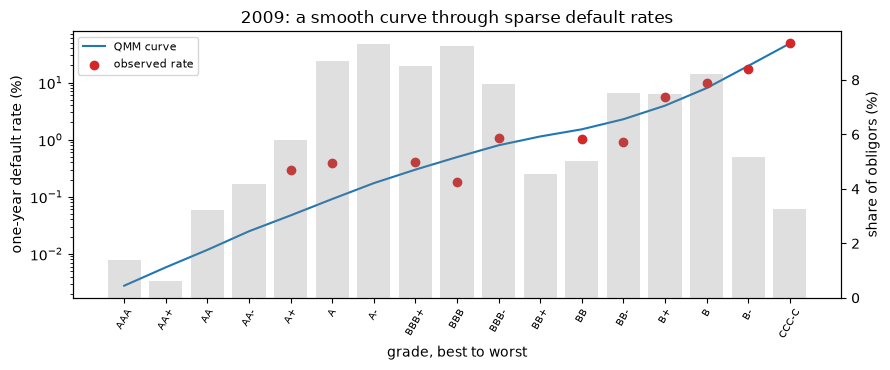

In [4]:
# Draw the 2009 default rates, the smoothed curve and the rating profile
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(grades))
seen = default_rate0 > 0
ax.plot(x, 100 * curve0, color="tab:blue", label="QMM curve")
ax.scatter(x[seen], 100 * default_rate0[seen], color="tab:red", zorder=3, label="observed rate")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(grades, rotation=60, fontsize=7)
ax.set_xlabel("grade, best to worst")
ax.set_ylabel("one-year default rate (%)")
share = ax.twinx()
share.bar(x, 100 * profile0, color="grey", alpha=0.25)
share.set_ylabel("share of obligors (%)")
ax.set_title("2009: a smooth curve through sparse default rates")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

The red points scatter around the curve and are absent for the six best grades, where no obligor defaulted: a rate of zero is not a PD of zero, and the curve gives those grades a small positive PD instead. The grey bars show that the obligors concentrate between A- and BB and again at B, so the curve's behaviour there, more than at either end, drives the unconditional PD. The figure does not show that two parameters are enough for every year; it shows that they are enough to follow the 2009 points that exist.

### Step 2: nine ways to carry the curve to a new year

Tasche's approaches sort by what the bank knows when the new year starts. In **case 1** it knows the new rating profile and the PD: the invariant default profile (A1), the invariant accuracy ratio (A2), scaled PDs (A3) and the scaled likelihood ratio (A4). In **case 2** it knows the PD under the old profile only (B1, invariant likelihood ratio). In **case 3** it knows only the new profile: the invariant PD curve, that is, last year's curve unchanged (C1), two fits of invariant conditional profiles (C2 by least squares, C3 by least chi-square) and the invariant likelihood ratio with the profile known (C4). The next cell computes the nine curves for 2010 and 2011 with the engine's `pd_curve` functions, and the PD that each approach forecasts. Cases 1 and 2 are given the PD, so for A1 to A4 it is the observed one; case 3 must infer it.

In [5]:
# Carry the 2009 curve to 2010 and 2011 with the nine approaches and read the PD each forecasts
curves, forecast = {}, {}
dp_start = pc.implied_default_profile(curve0, base["profile0"])
sv_start = pc.implied_survival_profile(curve0, base["profile0"])
for year, doc in years.items():
    o = doc["outputs"]
    p1, pd1 = o["profile1"], o["pd1"]
    new = {
        "A1-idp": pc.invariant_default_profile(o["default_profile0"], p1, pd1),
        "A2-iar": pc.invariant_accuracy_ratio(p1, pd1, o["ar0"]),
        "A3-spd": pc.scaled_pds(curve0, p1, pd1),
        "A4-slr": pc.scaled_likelihood_ratio(curve0, start["pd"], p1, pd1),
        "B1-ilr": pc.invariant_likelihood_ratio(curve0, start["pd"], pd_1=pd1),
        "C1-ipc": pc.invariant_pd_curve(curve0, p1),
        "C2-ls": pc.invariant_conditional_profiles(dp_start, sv_start, p1, fit="least_squares"),
        "C3-chi2": pc.invariant_conditional_profiles(dp_start, sv_start, p1, fit="least_chi2"),
        "C4-ilr": pc.invariant_likelihood_ratio(curve0, start["pd"], profile_1=p1),
    }
    curves[year] = {aid: np.array(r["pd_curve"]) for aid, r in new.items()}
    own = ("C2-ls", "C3-chi2", "C4-ilr")  # these infer the PD themselves
    forecast[year] = {a: r["pd"] if a in own else pc.unconditional_pd(r["pd_curve"], p1) for a, r in new.items()}
ids = list(curves[2010])
for year, doc in years.items():
    pd1 = doc["outputs"]["pd1"]
    print(f"{year}: observed PD {pd1:.4f}, defaults {doc['outputs']['n_defaults']}")
    print("  forecast / observed:", {a[:2]: round(forecast[year][a] / pd1, 2) for a in ids})

2010: observed PD 0.0114, defaults 63
  forecast / observed: {'A1': 1.0, 'A2': 1.0, 'A3': 1.0, 'A4': 1.0, 'B1': 1.36, 'C1': 3.78, 'C2': 4.21, 'C3': 4.69, 'C4': 4.71}
2011: observed PD 0.0075, defaults 44
  forecast / observed: {'A1': 1.0, 'A2': 1.0, 'A3': 1.0, 'A4': 1.0, 'B1': 1.15, 'C1': 4.99, 'C2': 4.65, 'C3': 3.77, 'C4': 3.71}


The figure draws the forecast PD over the observed PD for each approach, in both years. A bar at one is a forecast equal to what was observed.

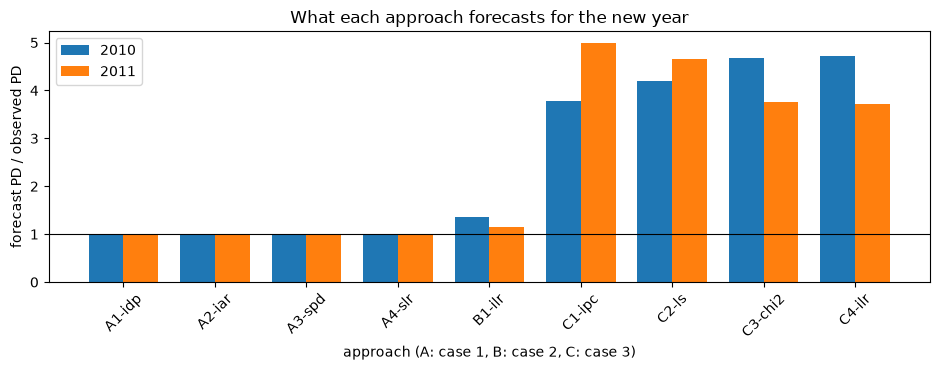

In [6]:
# Draw the forecast PD over the observed PD by approach, both years
fig, ax = plt.subplots(figsize=(9.5, 3.8))
width = 0.38
for k, year in enumerate(years):
    ratio = [forecast[year][a] / years[year]["outputs"]["pd1"] for a in ids]
    ax.bar(np.arange(len(ids)) + (k - 0.5) * width, ratio, width, label=str(year))
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_xticks(range(len(ids)))
ax.set_xticklabels(ids, rotation=45)
ax.set_xlabel("approach (A: case 1, B: case 2, C: case 3)")
ax.set_ylabel("forecast PD / observed PD")
ax.set_title("What each approach forecasts for the new year")
ax.legend()
fig.tight_layout()
plt.show()

The first four bars are exactly one in both years because those approaches are handed the PD: they cannot be wrong about it. B1 is handed the PD under the old profile and so lands a little above one, about 1.4 in 2010 and 1.15 in 2011. The case 3 approaches have to infer the PD from the profile alone, and all four miss by a factor of about four to five in both years, in the same direction: they start from the 2009 PD of 3.99% and the profile does not reveal that the year was calmer. The figure says that not knowing the PD is expensive; it does not say which of the case 3 approaches is least bad, since their order flips between the years.

## State of the art

### What the research found, and what the product does

- **Scaling the PDs is questionable.** Tasche (2013) shows that multiplying the old PD curve by a constant, the practice that is simple and widespread, is theoretically questionable, and that the invariant accuracy ratio by quasi moment matching and the scaled likelihood ratio perform much better. *Product:* all four are computed above and compared below.
- **Carrying the old curve unchanged.** The invariant PD curve is what a bank does when it keeps last year's calibration. *Product:* it is computed as C1 and its price is shown: a forecast PD several times the observed and the largest risk weight.
- **Other rungs.** The research lists intercept recalibration, Platt scaling and isotonic regression as ways to calibrate a model's scores to PDs, and Bayesian priors for low-default portfolios. *Product:* these work on scores, not on a rating profile, and are outside the approaches compared here; the Jeffreys intervals of notebook 02 are the posterior of a Beta prior, and no further prior is fitted.
- **The comparison is a one-year result.** Two forecast years are two samples; the committed tests say which approach is consistent with the year's defaults, not which is right in general. The product states the limit and does not rank the approaches beyond it.

Four readings compare the approaches on the two forecast years. The first, the PD forecast against the PD observed, is in the figure above. The second is the accuracy ratio each curve implies under the new rating profile, against the one observed in the year: how much of the ranking power of the ratings the curve keeps. The third asks whether the defaults fell on the grades as each curve implies, by comparing the default profile each curve implies with the observed one. The fourth is the average IRB risk weight each curve gives, which is what the choice costs in capital. One year has 63 defaults in 2010 and 44 in 2011 over 17 grades, and most grades have none or one: the third reading cannot be expected to separate every pair.

In [7]:
# The accuracy ratio each curve implies under the new rating profile, against the one observed in the year
ar_curve = {}
for year, doc in years.items():
    o = doc["outputs"]
    ar_curve[year] = {a: pc.accuracy_ratio_from_curve(curves[year][a], o["profile1"]) for a in ids}
    low, high = min(ar_curve[year].values()), max(ar_curve[year].values())
    print(f"{year}: observed accuracy ratio {o['ar1']:.4f}, 2009 {o['ar0']:.4f}")
    print(f"{year}: nine curves, from {low:.4f} to {high:.4f}")

2010: observed accuracy ratio 0.9015, 2009 0.8271
2010: nine curves, from 0.7935 to 0.8451
2011: observed accuracy ratio 0.8867, 2009 0.8271
2011: nine curves, from 0.7753 to 0.8271


The accuracy ratio of the year rose from 0.8271 in 2009 to 0.9015 in 2010 and 0.8867 in 2011: the ratings separated defaulters from survivors better than before. None of the nine curves follows that rise. They imply ratios between 0.7935 and 0.8451 in 2010 and between 0.7753 and 0.8271 in 2011, because a curve carried from a coarser year cannot reproduce the sharper separation of a year with few defaults. The invariant accuracy ratio keeps the 2009 value by construction, 0.8271, the highest of the nine in 2011. Ranking power is thus a reading on which the approaches stay close to each other and all fall short of the observation, so it does not favour the case 1 approaches over the case 3 ones.

In [8]:
# The default profile each curve implies under the new rating profile, against the observed one
distance, implied, observed = {}, {}, {}
for year, doc in years.items():
    o = doc["outputs"]
    seen = np.array(o["profile1"]) * np.array(o["default_rate1"])
    observed[year] = seen / seen.sum()
    implied[year] = {a: np.array(pc.implied_default_profile(curves[year][a], o["profile1"])) for a in ids}
    distance[year] = {a: float(np.abs(np.cumsum(implied[year][a]) - np.cumsum(observed[year])).max()) for a in ids}
    ranked = sorted(ids, key=distance[year].get)
    print(f"{year}: share of the defaults in the worst grade {observed[year][-1]:.3f}")
    print(f"{year}: largest gap, smallest to largest")
    print("  ", ", ".join(f"{a[:2]} {distance[year][a]:.3f}" for a in ranked))

2010: share of the defaults in the worst grade 0.778
2010: largest gap, smallest to largest
   A4 0.234, B1 0.247, A2 0.271, A1 0.325, A3 0.332, C1 0.332, C2 0.350, C3 0.361, C4 0.362
2011: share of the defaults in the worst grade 0.500
2011: largest gap, smallest to largest
   A2 0.093, A4 0.122, B1 0.125, A1 0.134, C4 0.176, C3 0.177, C2 0.191, C1 0.200, A3 0.200


The figure draws the cumulative default profile, grade by grade from the best to the worst, for the observed defaults and for four of the curves: the invariant PD curve (C1), scaled PDs (A3), the scaled likelihood ratio (A4) and the invariant accuracy ratio (A2).

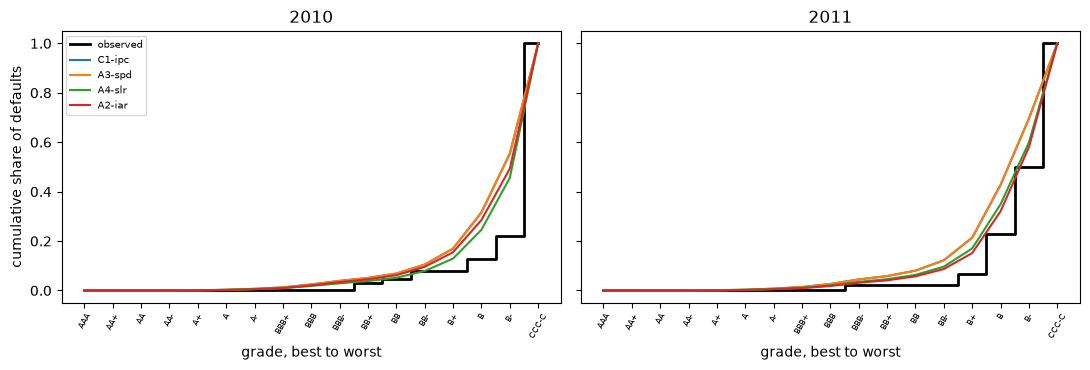

In [9]:
# Draw the cumulative default profile, observed and implied by four curves
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, year in zip(axes, years):
    ax.step(range(len(grades)), np.cumsum(observed[year]), where="mid", color="black", linewidth=2, label="observed")
    for a in ("C1-ipc", "A3-spd", "A4-slr", "A2-iar"):
        ax.plot(range(len(grades)), np.cumsum(implied[year][a]), label=a)
    ax.set_xticks(range(len(grades)))
    ax.set_xticklabels(grades, rotation=60, fontsize=6)
    ax.set_xlabel("grade, best to worst")
    ax.set_title(str(year))
axes[0].set_ylabel("cumulative share of defaults")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

In both years the black staircase stays below every curve until the last grades and then jumps: the defaults concentrate in the worst grade, 78% of the 63 defaults of 2010 and 50% of the 44 of 2011, more than any curve expects, and the curves expect more defaults in the B grades than occurred. In 2010 the scaled likelihood ratio (green) lies closest to the staircase and scaled PDs furthest of the four drawn. The blue line of the unchanged 2009 curve is hidden under the orange of scaled PDs: scaling a curve by a constant does not change the shape of its default profile, so the shape alone cannot tell the two apart, and only their forecast PD, in the first figure, does. The distances printed above are one number per curve, the largest gap between the cumulative lines. They compare shapes only; the chi-square test, read next, adds how many defaults there were to see the shape with.

The chi-square test of the implied default profile asks whether the observed defaults are consistent with the profile each curve implies. It is a Monte Carlo test on grade counts, which are not committed for this licence class, so it is read from the committed `tests` and not recomputed: its p-value and light for each approach and year, and the Monte Carlo standard error of every p-value. A p-value below 5% turns the light amber.

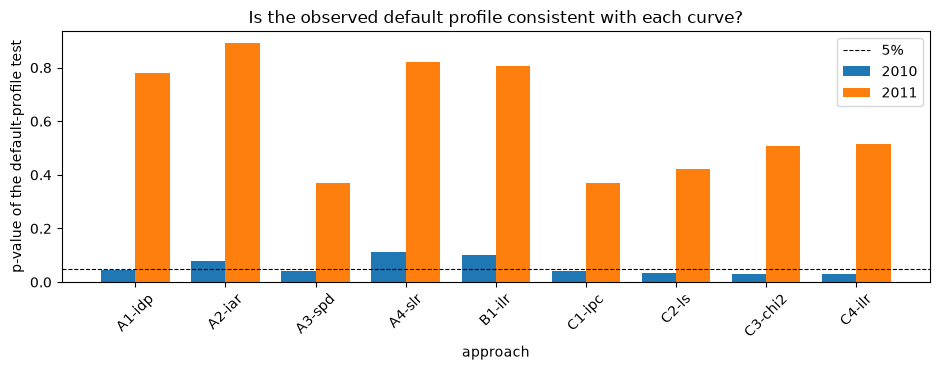

2010 tests baked by riskvalidation 1.0.1 | installed 1.0.1
2010 p: {'A1': 0.046, 'A2': 0.079, 'A3': 0.042, 'A4': 0.111, 'B1': 0.101, 'C1': 0.042, 'C2': 0.034, 'C3': 0.029, 'C4': 0.029}
2010 amber or red: ['A1-idp', 'A3-spd', 'C1-ipc', 'C2-ls', 'C3-chi2', 'C4-ilr']
2011 tests baked by riskvalidation 1.0.1 | installed 1.0.1
2011 p: {'A1': 0.782, 'A2': 0.891, 'A3': 0.37, 'A4': 0.82, 'B1': 0.808, 'C1': 0.37, 'C2': 0.421, 'C3': 0.51, 'C4': 0.515}
2011 amber or red: []
largest Monte Carlo standard error of a p-value: 0.0016


In [10]:
# Draw the committed p-values of the default-profile test by approach and year
tests = {}
for year, doc in years.items():
    rows = [t for t in doc["tests"] if t["test_id"] == "pd.default_profile"]
    tests[year] = {t["model_id"]: t for t in rows}
fig, ax = plt.subplots(figsize=(9.5, 3.8))
width = 0.38
for k, year in enumerate(years):
    values = [tests[year][a]["p_value"] for a in ids]
    ax.bar(np.arange(len(ids)) + (k - 0.5) * width, values, width, label=str(year))
ax.axhline(0.05, color="black", linestyle="--", linewidth=0.8, label="5%")
ax.set_xticks(range(len(ids)))
ax.set_xticklabels(ids, rotation=45)
ax.set_xlabel("approach")
ax.set_ylabel("p-value of the default-profile test")
ax.set_title("Is the observed default profile consistent with each curve?")
ax.legend()
fig.tight_layout()
plt.show()
for year in years:
    amber = [a for a in ids if tests[year][a]["light"] != "green"]
    baked = years[year]["provenance"]["riskvalidation_version"]
    print(year, "tests baked by riskvalidation", baked, "| installed", md.version("riskvalidation"))
    print(year, "p:", {a[:2]: round(tests[year][a]["p_value"], 3) for a in ids})
    print(year, "amber or red:", amber)
errors = [t["extras"]["mc_standard_error"] for y in tests for t in tests[y].values()]
print("largest Monte Carlo standard error of a p-value:", round(max(errors), 4))

The tests separate the years more than the approaches. In 2011 every bar is above the dashed line, so all nine curves are consistent with the 44 defaults, and nothing can be ranked. In 2010 six are below it, the invariant default profile, scaled PDs and the four case 3 approaches, while the scaled likelihood ratio, the invariant accuracy ratio and case 2 stay above. Scaled PDs has the lowest p-value of case 1 in both years, which agrees with Tasche's warning. The Monte Carlo error of the p-values is small next to the gap of a few hundredths that separates the bars near the line, so the amber lights are not noise, but with 63 defaults mostly in the last grades the test has little left to tell the case 1 approaches apart.

Now the cost in capital. The next cell prices every grade of every curve with the engine's IRB function, under the case's assumptions (Basel III, corporate, LGD 45%, maturity 2.5 years, PD floor 0.05%), and averages the weights over the forecast year's rating profile.

In [11]:
# The average IRB risk weight of the forecast portfolio under each curve
spec = base["irb"]
settings = {"lgd": spec["lgd"], "maturity": spec["maturity"], "regime": spec["regime"]}
risk_weight, floored = {}, {}
for year, doc in years.items():
    mix = np.array(doc["outputs"]["profile1"])
    risk_weight[year], floored[year] = {}, {}
    for aid, curve in curves[year].items():
        results = [irb.capital_requirement(spec["asset_class"], float(p), **settings) for p in curve]
        risk_weight[year][aid] = float(mix @ np.array([r.risk_weight for r in results]))
        floored[year][aid] = sum(r.pd_applied != r.pd_input for r in results)
for year in years:
    anchored = [risk_weight[year][a] for a in ids[:5]]
    inferred = [risk_weight[year][a] for a in ids[5:]]
    print(f"{year}: cases 1 and 2 {min(anchored):.4f} to {max(anchored):.4f}")
    print(f"{year}: case 3 {min(inferred):.4f} to {max(inferred):.4f}")
    print(f"{year}: spread of the four case 1 weights {max(anchored[:4]) / min(anchored[:4]) - 1:.3f}")
    extra = [w / risk_weight[year]["A4-slr"] - 1 for w in inferred]
    print(f"{year}: case 3 over the scaled likelihood ratio")
    print(f"  {min(extra):.3f} to {max(extra):.3f}")
print("grades at the PD floor, 2010:", {a[:2]: floored[2010][a] for a in ids})

2010: cases 1 and 2 0.5504 to 0.6158
2010: case 3 0.9068 to 0.9850
2010: spread of the four case 1 weights 0.107
2010: case 3 over the scaled likelihood ratio
  0.648 to 0.790
2011: cases 1 and 2 0.4939 to 0.5347
2011: case 3 0.8280 to 0.9263
2011: spread of the four case 1 weights 0.083
2011: case 3 over the scaled likelihood ratio
  0.639 to 0.833
grades at the PD floor, 2010: {'A1': 6, 'A2': 7, 'A3': 7, 'A4': 7, 'B1': 7, 'C1': 5, 'C2': 4, 'C3': 4, 'C4': 4}


The figure draws the average risk weight of each approach in both years.

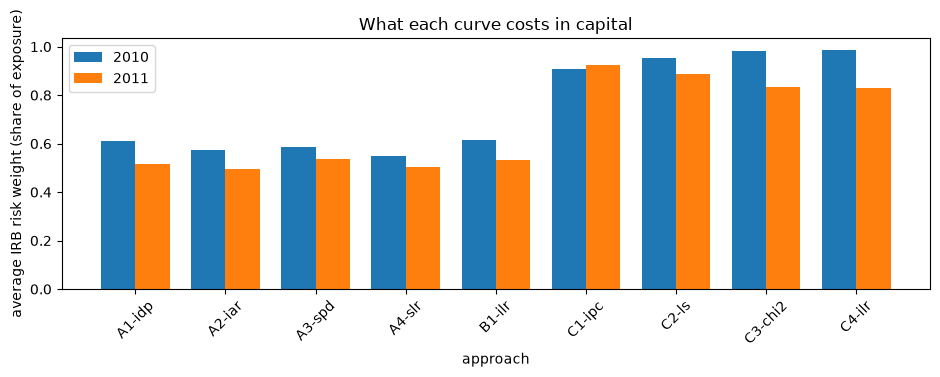

In [12]:
# Draw the average IRB risk weight by approach, both years
fig, ax = plt.subplots(figsize=(9.5, 3.8))
width = 0.38
for k, year in enumerate(years):
    ax.bar(np.arange(len(ids)) + (k - 0.5) * width, [risk_weight[year][a] for a in ids], width, label=str(year))
ax.set_xticks(range(len(ids)))
ax.set_xticklabels(ids, rotation=45)
ax.set_xlabel("approach")
ax.set_ylabel("average IRB risk weight (share of exposure)")
ax.set_title("What each curve costs in capital")
ax.legend()
fig.tight_layout()
plt.show()

The four case 1 approaches and case 2 weigh between 0.49 and 0.62, within about a tenth of one another, so the choice among them moves capital by far less than the gap to the next group. The case 3 approaches weigh 0.83 to 0.99, between 64% and 83% more than the scaled likelihood ratio, because their forecast PDs are four to five times the observed ones. The PD floor binds in the best six or seven grades of every curve that is anchored to the observed PD, so those grades weigh the same whichever approach is used. The figure prices the curves, not the year: it does not say what the portfolio's true PD will be in the years after.

## Results

**Answer:** No approach wins on every reading, but the scaled likelihood ratio (A4) comes closest to the 2010 year and the invariant accuracy ratio (A2) to 2011, while the approaches that must infer the PD fail by a wide margin. In 2010 the four case 1 approaches forecast the observed PD of 0.0114 by construction, case 2 forecasts 1.36 times it and the four case 3 approaches 3.78 to 4.71 times; in 2011, with an observed 0.0075, case 2 forecasts 1.15 times and case 3 3.71 to 4.99 times. A4 has the smallest gap to the 2010 default profile, 0.234, and a p-value of 0.111 against the 0.029 to 0.046 of the six amber approaches; in 2011 all nine have p-values from 0.370 and A2 has the smallest gap, 0.093. In capital the average IRB risk weight is 0.5504 to 0.6158 for cases 1 and 2 against 0.9068 to 0.9850 for case 3 in 2010, and 0.4939 to 0.5347 against 0.8280 to 0.9263 in 2011.

- **Forecast against observed.** The approaches of cases 1 and 2 are given the PD, so the four of case 1 are exact and B1 is 1.36 times the observed 0.0114 in 2010 and 1.15 times the observed 0.0075 in 2011. The case 3 approaches, which must infer it, start from the 2009 PD of 0.0399 and overshoot by a factor of about four to five in both years.
- **Ranking power.** The accuracy ratio rose from 0.8271 in 2009 to 0.9015 in 2010 and 0.8867 in 2011, and the nine curves imply 0.7935 to 0.8451 and 0.7753 to 0.8271: all fall short of it.
- **The default profile.** In 2010 the worst grade holds 0.778 of the defaults. A4, B1 and A2 are the closest curves (gaps 0.234, 0.247 and 0.271) and the amber lights are A1, A3, C1, C2, C3 and C4 (p from 0.029 to 0.046); in 2011 no light is amber and the p-values run from 0.370 to 0.891. A3 and C1 have the same default profile, hence the same gap (0.332 and 0.200) and the same p-value, and differ only in their PD. The Monte Carlo error of any p-value is at most 0.0016.
- **Capital.** The four case 1 weights spread by 0.107 in 2010 and 0.083 in 2011; case 3 weighs 0.648 to 0.790 more than the scaled likelihood ratio in 2010 and 0.639 to 0.833 more in 2011. The PD floor binds in 6 or 7 of the 17 grades under the curves anchored to the observed PD, so the good grades weigh the same whatever the approach.
- **What the comparison cannot say.** Two forecast years are two samples, and the default-profile test reads committed results that need grade counts, which the licence class keeps out of the repository. The comparison shows that not knowing the PD is costly and that one year cannot rank the case 1 approaches against each other in general.

What this notebook does not show: how the curves are built from the 2009 targets (notebook 05) or how the IRB function turns a PD into capital (notebook 07).

## Summary

- The approaches that know the year's profile and PD fit the 2010 defaults better than scaling the PDs or keeping the old curve; in 2011 nothing separates them.
- Not knowing the PD (case 3) forecasts four to five times the observed PD and costs 64% to 83% more capital than the scaled likelihood ratio.
- The chi-square test sees the shape of a curve with few defaults and does not rank the approaches in general; the product says so.
- The research practices on scores (Platt, isotonic, intercept) and Bayesian priors are not run on a rating profile here.

**What to try next.** Rebuild the curves from the 2009 targets of notebook 05 and ask which approach would have been chosen in advance; then read notebook 10.

## References

- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), 63-103, Tables 6 to 8 and sections 4.2 to 4.4. https://doi.org/10.21314/jcr.2013.169
- BCBS, Basel Framework, CRE32, IRB approach: risk-weighted asset calculation (LGD, maturity and PD floor). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Platt, J. (1999), Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods, in Advances in Large Margin Classifiers, MIT Press, for the rung the research lists.